# 2. Decomposition

Classical additive/multiplicative and robust STL. Owner: Prem — Phase 2.

In [7]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))
import os
os.chdir(project_root)

from src.decomposition import residual_summary, run_all
from src.eda import impute_linear, suggest_sarima_orders, adf_table
from src.load_data import load_daily_series
from src.plots import plot_decompose, save_current_figure

DATA_PATH = project_root / "data/processed/pm25_paris_daily.csv"
(project_root / "reports/figures").mkdir(parents=True, exist_ok=True)

series = impute_linear(load_daily_series(DATA_PATH))
series.head()

date
2023-01-01    10.004167
2023-01-02     6.608333
2023-01-03     7.954167
2023-01-04     4.141667
2023-01-05     4.937500
Freq: D, Name: pm25, dtype: float64

## Classical seasonal decomposition

Period = 7 (weekly). Additive assumes constant seasonal amplitude; multiplicative scales with the level.

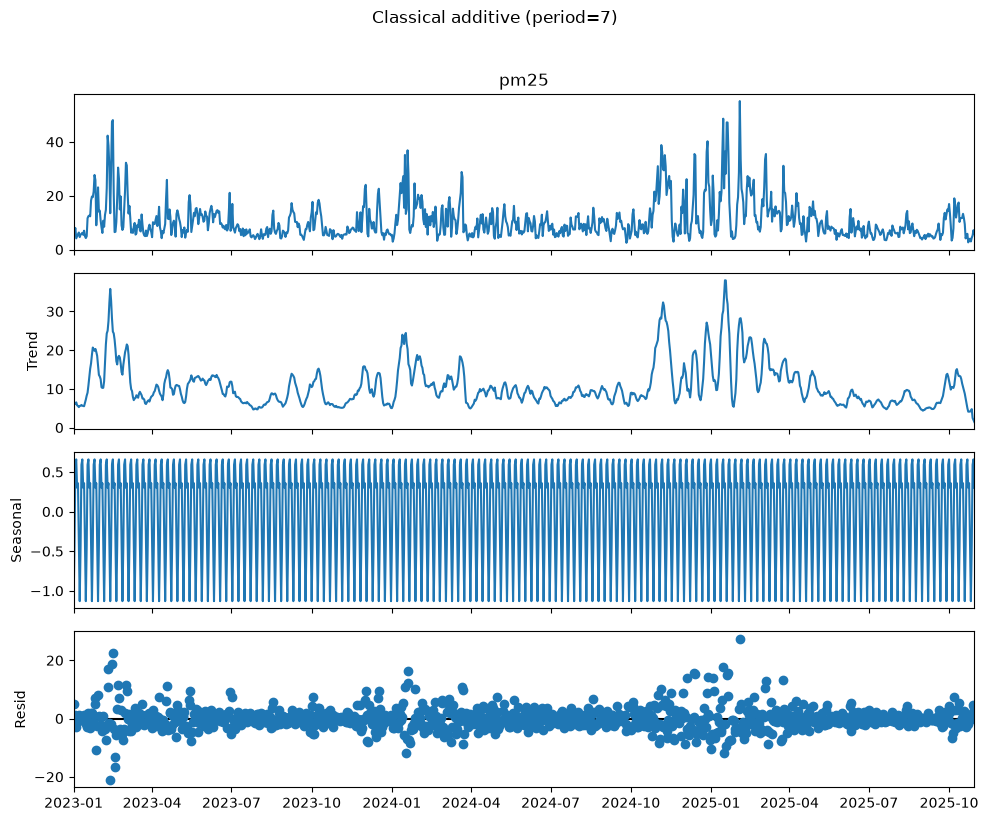

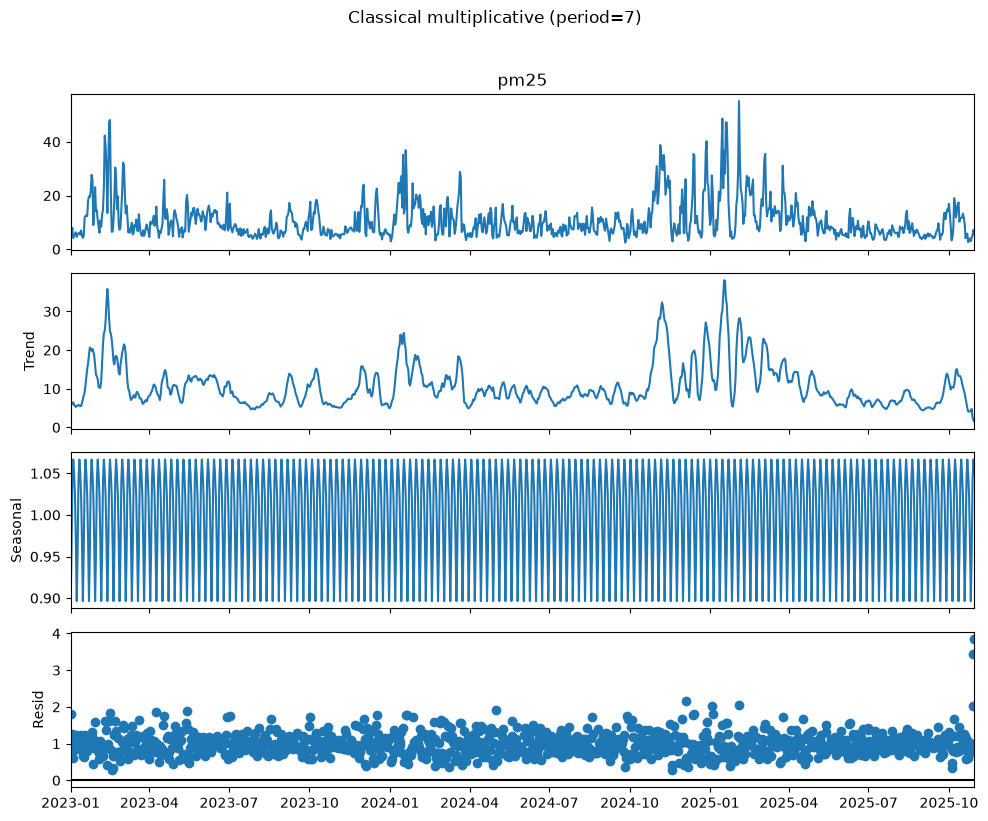

In [3]:
PERIOD = 7
bundle = run_all(series, period=PERIOD)

plot_decompose(bundle.additive, "Classical additive (period=7)")
save_current_figure("02_classical_additive.png")
plt.show()

plot_decompose(bundle.multiplicative, "Classical multiplicative (period=7)")
save_current_figure("02_classical_multiplicative.png")
plt.show()

## Robust STL decomposition

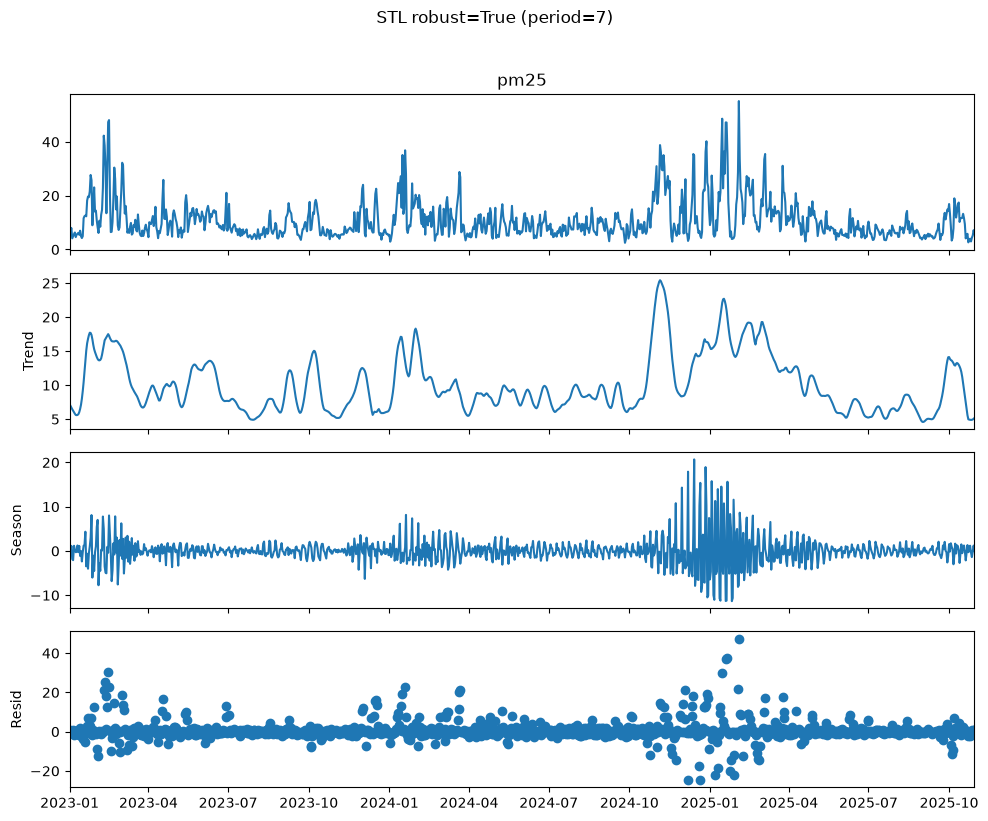

,method,resid_std,resid_mean,seasonal_amp
0,classical_additive,3.910864,0.013481,1.790451
1,classical_multiplicative,0.311854,0.994721,0.170117
2,stl_robust,5.274824,0.737064,32.024120


In [4]:
plot_decompose(bundle.stl, "STL robust=True (period=7)")
save_current_figure("02_stl_robust.png")
plt.show()

summary = pd.DataFrame(
    [
        residual_summary(bundle.additive, "classical_additive"),
        residual_summary(bundle.multiplicative, "classical_multiplicative"),
        residual_summary(bundle.stl, "stl_robust"),
    ]
)
summary

## Interpretation and suggested SARIMA orders

### Trend
The trend component captures the slow level of Paris PM2.5 (typically higher in colder months). Classical and STL agree on the broad shape; STL is smoother because LOESS down-weights short spikes.

### Seasonality
With `period=7` both methods show a clear weekly cycle (traffic / weekday activity). Multiplicative seasonality stretches when the level is high; additive keeps a fixed amplitude. For this series additive + STL are usually enough; multiplicative is kept as a comparison.

### Residuals
Residuals hold irregular pollution episodes and sensor noise. STL (`robust=True`) pushes more of those spikes into the residual than classical, which is useful later for Vishal’s anomaly detection on STL residuals.

### Classical vs STL
- Classical is fast and simple but sensitive to outliers.
- STL is more flexible (LOESS trend/seasonal) and robust mode limits outlier influence on the seasonal pattern.

### Orders for Yahya
See also `docs/sarima_orders_for_yahya.md`.

In [5]:
adf = adf_table(series)
prefer_diff = not bool(adf.loc[adf["series"] == "raw", "stationary_5pct"].iloc[0])
orders = suggest_sarima_orders(seasonal_period=PERIOD, prefer_diff=prefer_diff)
print("ADF table:")
display(adf)
print("Suggested SARIMA order:", orders["order"])
print("Suggested seasonal_order:", orders["seasonal_order"])
print("Starting points only: final orders are selected by AIC/BIC on the training set in 03_forecasting.ipynb.")

ADF table:


/home/soums/Documents/MesCours/MSc_AIS/AIS_S3/Time_Series_Analysis/tsa_project/src/eda.py:56: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, used_lag, nobs, *_ = adfuller(clean, autolag="AIC")
/home/soums/Documents/MesCours/MSc_AIS/AIS_S3/Time_Series_Analysis/tsa_project/src/eda.py:56: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pvalue, used_lag, nobs

,series,adf_stat,pvalue,used_lag,nobs,stationary_5pct
0,raw,-4.419287,2.743525e-04,14,1019,True
1,diff_1,-11.654238,2.003213e-21,18,1014,True


Suggested SARIMA order: (1, 0, 1)
Suggested seasonal_order: (1, 0, 1, 7)
Starting points only: final orders are selected by AIC/BIC on the training set in 03_forecasting.ipynb.


/tmp/ipykernel_46741/450472207.py:6: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * series.index.dayofyear.values / 365.25


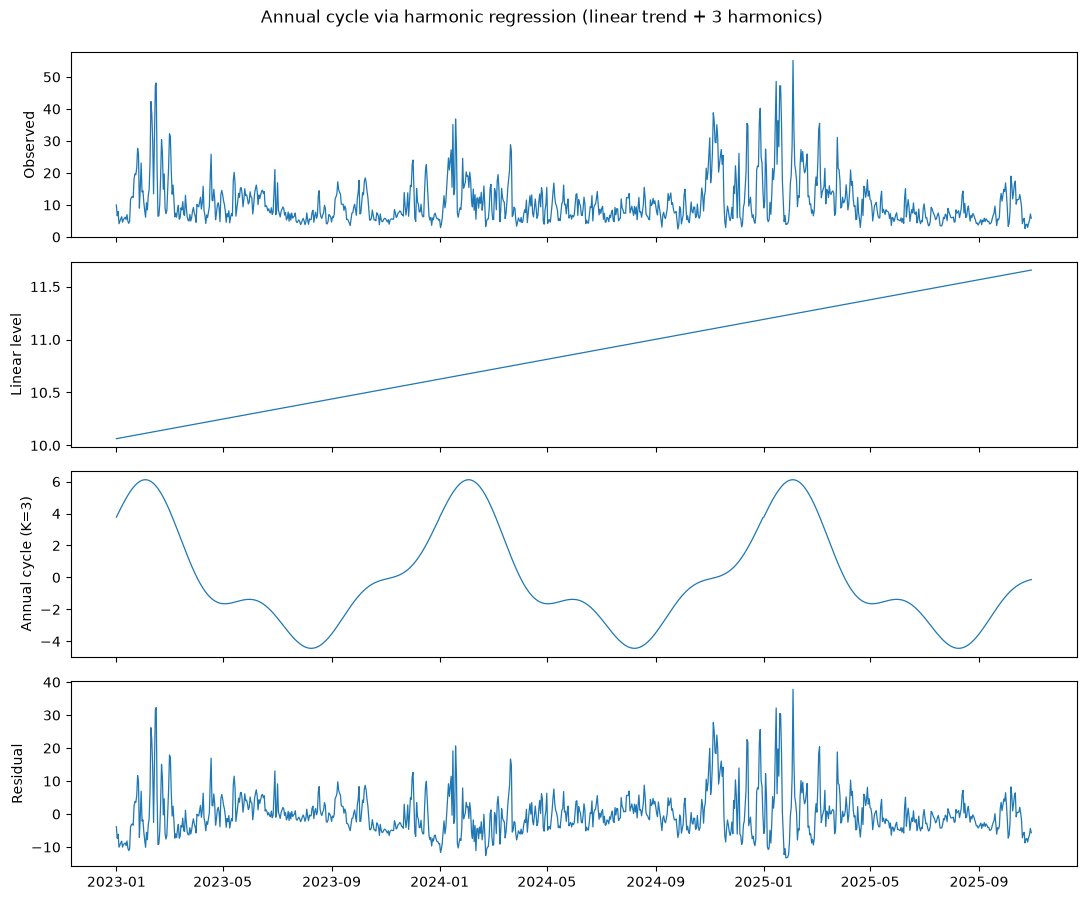

R² of trend + annual cycle: 0.187
Annual cycle amplitude (max - min): 10.56 µg/m³
Peak: 02-03   Trough: 08-09
Residual std: 6.40 (series std: 7.10)
Residual std winter (DJF): 9.90   summer (JJA): 3.01
Residual autocorrelation: lag 1 = 0.71, lag 7 = 0.05

Mean residual by day of week (after removing trend + annual cycle):
Mon   -0.44
Tue    0.57
Wed    0.64
Thu    0.27
Fri    0.40
Sat   -0.31
Sun   -1.14
dtype: float64


/tmp/ipykernel_46741/450472207.py:38: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = resid.groupby(resid.index.dayofweek).mean()


In [8]:
# Annual cycle via harmonic regression: linear trend + K annual Fourier terms
# (STL with period=365 is degenerate here: only ~2.8 cycles, each calendar day seen 2-3 times)
K = 3
n = len(series)
t = np.arange(n)
angle = 2 * np.pi * series.index.dayofyear.values / 365.25

cols = [np.ones(n), (t - t.mean()) / n]
for k in range(1, K + 1):
    cols += [np.sin(k * angle), np.cos(k * angle)]
X = np.column_stack(cols)

beta, *_ = np.linalg.lstsq(X, series.values, rcond=None)
level = pd.Series(X[:, :2] @ beta[:2], index=series.index)
seasonal = pd.Series(X[:, 2:] @ beta[2:], index=series.index)
resid = series - level - seasonal

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, (data, label) in zip(
    axes, [(series, "Observed"), (level, "Linear level"), (seasonal, "Annual cycle (K=3)"), (resid, "Residual")]
):
    ax.plot(data.index, data.values, linewidth=0.9)
    ax.set_ylabel(label)
fig.suptitle("Annual cycle via harmonic regression (linear trend + 3 harmonics)", y=0.995)
fig.tight_layout()
save_current_figure("02_annual_harmonic.png")
plt.show()

r2 = 1 - resid.var() / series.var()
print(f"R² of trend + annual cycle: {r2:.3f}")
print(f"Annual cycle amplitude (max - min): {seasonal.max() - seasonal.min():.2f} µg/m³")
print(f"Peak: {seasonal.idxmax():%m-%d}   Trough: {seasonal.idxmin():%m-%d}")
print(f"Residual std: {resid.std():.2f} (series std: {series.std():.2f})")
print(f"Residual std winter (DJF): {resid[resid.index.month.isin([12, 1, 2])].std():.2f}"
      f"   summer (JJA): {resid[resid.index.month.isin([6, 7, 8])].std():.2f}")
print(f"Residual autocorrelation: lag 1 = {resid.autocorr(1):.2f}, lag 7 = {resid.autocorr(7):.2f}")

dow = resid.groupby(resid.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("\nMean residual by day of week (after removing trend + annual cycle):")
print(dow.round(2))

## Interpretation

This series has two seasonal scales, and they behave very differently: a **weak weekly cycle** (period 7, decomposed above with classical and STL methods) and a **strong annual cycle** (decomposed with a harmonic regression, because a period-365 STL is not identifiable here).

### Seasonality
- **Weekly (period 7):** present but small. Day-of-week means differ by about 1.8 µg/m³ between Sunday (lowest) and Wednesday (highest), compared with a series standard deviation of 7.1. After removing trend and the annual cycle, residual autocorrelation at lag 7 is only 0.05. Weekday activity has a measurable but minor effect.
- **Annual:** a smooth cycle fitted with a linear level and 3 harmonics has a peak-to-trough amplitude of about 10.6 µg/m³, peaking around 3 February and bottoming around 9 August (monthly means: about 15 µg/m³ in winter against 8 in summer). This cycle explains only **about 19% of the daily variance** (R² = 0.19), so it dominates the *level* but not the day-to-day behaviour.

### Trend
- With a 7-day window, the classical/STL trend is not a long-term trend: it follows multi-day pollution episodes and the annual swing, and is only a smoothed version of the series.
- The linear level in the harmonic fit rises slightly, from about 10.1 to 11.7 µg/m³ over 2023-2025. Yearly means (10.2, 11.2, 11.0) are consistent with a small, unreliable change. With under three years of data, a long-term trend cannot be separated from year-to-year weather differences.

### Residuals
- After removing the annual cycle, residuals are still strongly autocorrelated at lag 1 (0.71): short pollution episodes lasting several days remain. This is the structure that the AR terms capture in the ARIMA models.
- Residual variability depends on the season: the standard deviation is about 9.9 in winter (Dec-Feb) against 3.0 in summer (Jun-Aug). The residuals are heteroscedastic, so a variance-stabilizing transform (log) or season-dependent thresholds would be needed for anomaly detection on the residuals.

### Classical vs STL (period 7)
- Classical decomposition is fast and simple, but sensitive to outliers, and its seasonal pattern is a plain average over weeks.
- STL with `robust=True` limits the influence of spikes on the seasonal estimate, and moves more of the spikes into the residual.
- The multiplicative model is kept as a comparison. Its seasonal component and residual are ratios (around 1), so `seasonal_amp` and `resid_std` in the summary table are not comparable in absolute value with the additive and STL rows. The variance does grow with the level, which would favour a multiplicative or log model for the annual component, but at period 7 the seasonal effect is small either way.

### Why not a period-365 STL?
Tried and rejected: with about 2.8 years of data, each calendar day is observed only 2-3 times, and STL almost memorizes them. The seasonal component came out with a variance equal to 103% of the series variance, residuals were near zero except during 2024, and the trend was an artefact. The harmonic regression above is used instead, because its 8 parameters cannot memorize individual years.

### Starter SARIMA orders
The orders printed below are starting points only. Because the weekly seasonality is weak, seasonal differencing (`D = 1`) over-differences this series, so final orders are selected by AIC/BIC on the training set in `03_forecasting.ipynb` (see also `docs/sarima_orders_for_yahya.md`).